# Cirq · 离散欧式期权定价

Discrete European option pricing

[金融 Cirq 总目录](cirq_finance.html) · **QuantumBridge 原创金融教学扩展 / Cirq 本地仿真**

离散风险中性情景加收益辅助比特，展示折现价格与采样误差。

合成模型；不是投资建议，不是完整行业支持，也不证明 QuantumBridge 原生替代 Cirq。

## 1. 官方方法与归属 / Sources

这是 QuantumBridge 用 Cirq API 编写的金融教学扩展，不是 Google 官方期权教程。使用普通采样而非 QAE；未实现动态对冲、路径依赖、多资产定价或量子加速。

- [Google Cirq · Simulation](https://quantumai.google/cirq/simulate/simulation)

## 2. 原理与步骤 / Model & workflow

假定到期价格 $S_T=(80,95,110,130)$，风险中性概率 $Q=(0.55,0.25,0.15,0.05)$，
$K=100,r=0.02,T=1$。这些是自定义离散风险中性模型，隐含现货
$S_0=e^{-rT}E_Q[S_T]$，不是从行情校准或复刻 Black–Scholes。
为每个情景在辅助位施加 $RY(2\arcsin\sqrt{(S_T-K)^+/30})$，
则 $P(a=1)=E_Q[(S_T-K)^+]/30=0.1$；价格 $C=e^{-rT}30P(a=1)$。
95% Wilson 区间仅表示二项抽样不确定性，不包含模型和硬件误差。

声明风险中性假设和隐含现货 → 制备情景 → 受控收益旋转 → 检查辅助位精确概率 → 4096 shots → 折现价格与 Wilson 区间。

## 3. 运行环境 / Local environment

需要已安装 `cirq`、`numpy`、`matplotlib` 与 Jupyter。代码不依赖本仓库私有模块，可在安装上述依赖的 Python 内核从上到下运行。没有自动安装、联网或密钥读取。

In [1]:
import json, sys
import cirq
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML

SEED, SHOTS = 20261101, 4096
simulator = cirq.Simulator(dtype=np.complex128, seed=SEED)
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
print('Backend: local cirq.Simulator | Cirq:', cirq.__version__)
print('Python:', sys.version.split()[0], '| hardware jobs: 0')
print('Bit order: q0 first / most significant bit; synthetic data only.')

def probabilities(circuit, qubits):
    state = simulator.simulate(circuit, qubit_order=qubits).final_state_vector
    return np.abs(state)**2

def measured_counts(circuit, qubits, key='out'):
    measured = circuit + cirq.Circuit(cirq.measure(*qubits, key=key))
    histogram = simulator.run(measured, repetitions=SHOTS).histogram(key=key)
    return np.array([histogram.get(i, 0) for i in range(2**len(qubits))], dtype=int)

def compare_plot(labels, exact, sampled, title):
    x = np.arange(len(labels))
    fig, ax = plt.subplots(figsize=(8, 3.3), layout='constrained')
    ax.bar(x-.18, exact, .36, label='Exact model', color='#137f76')
    ax.bar(x+.18, sampled, .36, label='4096 local Cirq shots', color='#bc4164')
    ax.set(xticks=x, xticklabels=labels, ylabel='Probability', title=title)
    ax.legend()
    plt.show()

Backend: local cirq.Simulator | Cirq: 1.6.1
Python: 3.12.6 | hardware jobs: 0
Bit order: q0 first / most significant bit; synthetic data only.


## 4. 输入与电路 / Inputs & circuit

In [2]:
scenarios = list(cirq.LineQubit.range(2))
ancillary = cirq.LineQubit(2)
p = np.array([.55,.25,.15,.05])
terminal = np.array([80.,95.,110.,130.])
rate, maturity, strike, scale = .02, 1., 100., 30.
payoff = np.maximum(terminal-strike, 0)

## 5. 中间结果与实际本地采样 / Intermediate & sampled results

图中 Exact 为同一模型的精确分布；Cirq shots 为有限次模拟测量，不是真机回执。

Terminal / probability / payoff: [(np.float64(80.0), np.float64(0.55), np.float64(0.0)), (np.float64(95.0), np.float64(0.25), np.float64(0.0)), (np.float64(110.0), np.float64(0.15), np.float64(10.0)), (np.float64(130.0), np.float64(0.05), np.float64(30.0))]
Implied spot: 88.95302960258805
Ancillary success probability: 0.1
Circuit:
0: ───Ry(0.295π)───(0)──────────@────────────(0)─────(0)─────@────────────@───────
                   │            │            │       │       │            │
1: ────────────────Ry(0.378π)───Ry(0.333π)───(0)─────@───────(0)──────────@───────
                                             │       │       │            │
2: ──────────────────────────────────────────Ry(0)───Ry(0)───Ry(0.392π)───Ry(π)───


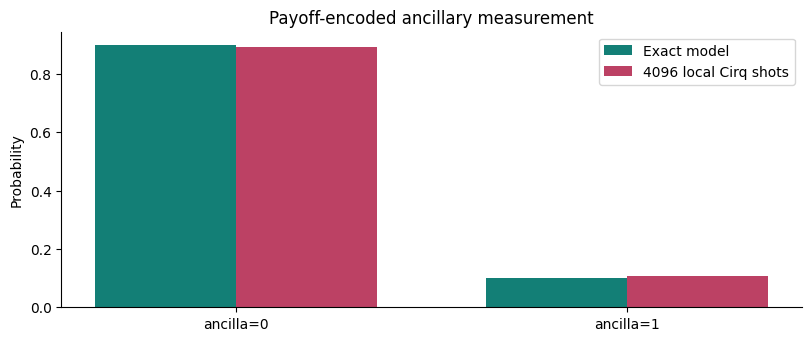

In [3]:
def prepare_four(probabilities, qubits):
    p = np.asarray(probabilities, dtype=float)
    assert p.shape == (4,) and np.all(p > 0) and np.isclose(p.sum(), 1)
    left = p[0] + p[1]
    circuit = cirq.Circuit(cirq.ry(2*np.arccos(np.sqrt(left)))(qubits[0]))
    circuit.append(cirq.ry(2*np.arccos(np.sqrt(p[0]/left)))(qubits[1])
                   .controlled_by(qubits[0], control_values=[0]))
    circuit.append(cirq.ry(2*np.arccos(np.sqrt(p[2]/(1-left))))(qubits[1])
                   .controlled_by(qubits[0], control_values=[1]))
    return circuit

circuit = prepare_four(p, scenarios)
for i, value in enumerate(payoff):
    bits = [int(c) for c in f'{i:02b}']
    circuit.append(cirq.ry(2*np.arcsin(np.sqrt(value/scale)))(ancillary)
                   .controlled_by(*scenarios, control_values=bits))
exact = probabilities(circuit, [*scenarios, ancillary]).reshape(4, 2)
success = float(exact[:,1].sum())
discount = float(np.exp(-rate*maturity))
reference = float(discount*(p@payoff))
assert np.allclose(exact.sum(axis=1), p, atol=1e-12)
assert np.isclose(success, .1) and np.isclose(success*scale*discount, reference)
print('Terminal / probability / payoff:', list(zip(terminal, p, payoff)))
print('Implied spot:', discount*(p@terminal))
print('Ancillary success probability:', success)
print('Circuit:', circuit, sep='\n')
counts = measured_counts(circuit, [ancillary])
estimate = float(counts[1]/SHOTS)
z = 1.959963984540054
center = (estimate+z*z/(2*SHOTS))/(1+z*z/SHOTS)
half = z*np.sqrt(estimate*(1-estimate)/SHOTS+z*z/(4*SHOTS**2))/(1+z*z/SHOTS)
interval = [(center-half)*scale*discount, (center+half)*scale*discount]
compare_plot(['ancilla=0', 'ancilla=1'], [1-success, success], counts/SHOTS,
             'Payoff-encoded ancillary measurement')
evidence = {'qubits': 3, 'shots': SHOTS, 'counts': counts.tolist(),
            'exact_price': reference, 'sampled_price': estimate*scale*discount,
            'price_95pct_wilson_interval': interval,
            'implied_spot': float(discount*(p@terminal)),
            'ancilla_ideal_probability': success,
            'validation': 'Scenario marginal and discounted expected payoff checked'}

## 6. 最终输出与边界 / Evidence & limitations

这是 QuantumBridge 用 Cirq API 编写的金融教学扩展，不是 Google 官方期权教程。使用普通采样而非 QAE；未实现动态对冲、路径依赖、多资产定价或量子加速。

本次硬件任务为 0。不同 SDK 版本的随机抽样序列可能不同，解析断言仍应成立。

In [4]:
evidence.update({'backend': 'local cirq.Simulator', 'cirq_version': cirq.__version__, 'python': sys.version.split()[0], 'seed': SEED, 'hardware_jobs': 0})
print('EVIDENCE_JSON=' + json.dumps(evidence, ensure_ascii=False, allow_nan=False))

EVIDENCE_JSON={"qubits": 3, "shots": 4096, "counts": [3659, 437], "exact_price": 2.9405960199202656, "sampled_price": 3.1373058122684476, "price_95pct_wilson_interval": [2.8700484142704323, 3.426236761282813], "implied_spot": 88.95302960258805, "ancilla_ideal_probability": 0.1, "validation": "Scenario marginal and discounted expected payoff checked", "backend": "local cirq.Simulator", "cirq_version": "1.6.1", "python": "3.12.6", "seed": 20261101, "hardware_jobs": 0}
